# ETF Accumulation with Yearly Withdrawal

Accumulate capital in an ETF with monthly savings, extract a fixed percentage every year (e.g. a 4%-rule style drawdown). What passive monthly income does this produce?

Runs on the single unified model in `src/financial_model.py` (`etf_yearly_withdrawal_rate` parameter). The withdrawal is taken at each year end and is *not* reinvested; with `etf_tax_rate` set, capital gains tax is applied to the gain part of each withdrawal (`yearly_etf_withdrawal_net`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

ROOT_DIR = Path("/Users/pkoshkin/code/personal/finantial-tools")
import sys
sys.path.append(str(ROOT_DIR))

from src.financial_model import (
    Scenario,
    simulate,
    replace,
    payoff_year,
    calculate_early_repayment_penalty,
)

In [2]:
START_CAPITAL = 130_000
ETF_YEARLY_RETURN_RATE = 7 / 100
YEARLY_WITHDRAWAL_RATE = 4 / 100
MONTHLY_SAVING = 2_500
YEARS = 15
ETF_TAX_RATE = 26.375 / 100  # Abgeltungssteuer 25% + Soli 5.5%

scenario = Scenario(
    years=YEARS,
    initial_capital=START_CAPITAL,
    monthly_net_income=MONTHLY_SAVING,
    etf_yearly_return_rate=ETF_YEARLY_RETURN_RATE,
    etf_yearly_withdrawal_rate=YEARLY_WITHDRAWAL_RATE,
    etf_tax_rate=ETF_TAX_RATE,
)
model = simulate(scenario)
model

,year,total_loan,property_value,property_equity,etf_capital,etf_cost_basis,etf_capital_after_tax,estimated_total_capital,invested_capital,monthly_income,...,monthly_interest_payment,monthly_loan_repayment,monthly_mortgage_payment,monthly_housing_cost,monthly_leftover,yearly_sondertilgung,cumulative_interest_paid,yearly_etf_withdrawal_gross,yearly_etf_withdrawal_net,monthly_costs_not_covered_by_safe_withdrawal
0,0,0.0,0.0,0.0,130000.000000,130000.000000,130000.000000,130000.000000,130000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,0.000000,0.000000,-325.000000
1,1,0.0,0.0,0.0,163248.713149,153600.000000,160703.865056,160703.865056,160000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,6802.029715,6695.994377,-401.759663
2,2,0.0,0.0,0.0,197401.791296,176256.000000,191824.588842,191824.588842,190000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,8225.074637,7992.691202,-479.561472
3,3,0.0,0.0,0.0,232483.833169,198005.760000,223390.241370,223390.241370,220000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,9686.826382,9307.926724,-558.475603
4,4,0.0,0.0,0.0,268520.106580,218885.529600,255428.986902,255428.986902,250000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,11188.337774,10642.874454,-638.572467
5,5,0.0,0.0,0.0,305536.566628,238930.108416,287969.113275,287969.113275,280000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,12730.690276,11998.713053,-719.922783
6,6,0.0,0.0,0.0,343559.874390,258172.904079,321039.060970,321039.060970,310000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,14314.994766,13376.627540,-802.597652
7,7,0.0,0.0,0.0,382617.416122,276645.987916,354667.451933,354667.451933,340000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,15942.392338,14777.810497,-886.668630
8,8,0.0,0.0,0.0,422737.322990,294380.148400,388883.118192,388883.118192,370000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,17614.055125,16203.463258,-972.207795
9,9,0.0,0.0,0.0,463948.491325,311404.942464,423715.130313,423715.130313,400000.0,2500.0,...,0.0,0.0,0.0,0.0,2500.0,0.0,0.0,19331.187139,17654.797096,-1059.287826


In [3]:
final_capital = model['etf_capital'].iloc[-1]
monthly_income_gross = final_capital * YEARLY_WITHDRAWAL_RATE / 12
last = model.iloc[-1]

print(f"Start capital:            €{START_CAPITAL:>12,.2f}")
print(f"ETF growth/year:          {ETF_YEARLY_RETURN_RATE*100:>12.1f}%")
print(f"Yearly extraction:        {YEARLY_WITHDRAWAL_RATE*100:>12.1f}%")
print(f"Monthly saving:           €{MONTHLY_SAVING:>12,.2f}")
print(f"Investment horizon:       {YEARS:>12} years")
print("-" * 46)
print(f"Final capital:            €{final_capital:>12,.2f}")
print(f"Monthly income (gross):   €{monthly_income_gross:>12,.2f}")
print(f"Last-year withdrawal:     €{last['yearly_etf_withdrawal_gross']:>12,.2f} gross")
print(f"                          €{last['yearly_etf_withdrawal_net']:>12,.2f} net of tax")

Start capital:            €  130,000.00
ETF growth/year:                   7.0%
Yearly extraction:                 4.0%
Monthly saving:           €    2,500.00
Investment horizon:                 15 years
----------------------------------------------
Final capital:            €  735,851.96
Monthly income (gross):   €    2,452.84
Last-year withdrawal:     €   30,660.50 gross
                          €   26,971.48 net of tax


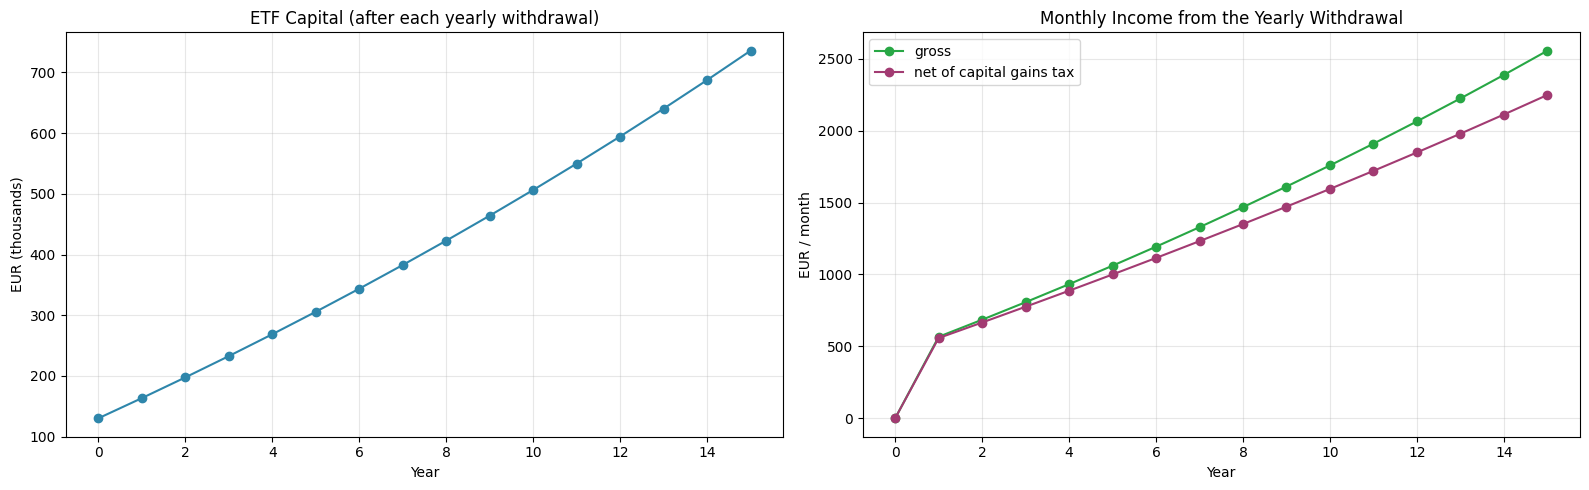

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(model['year'], model['etf_capital'] / 1000, '-o', color='#2E86AB')
axes[0].set_title('ETF Capital (after each yearly withdrawal)')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('EUR (thousands)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(model['year'], model['yearly_etf_withdrawal_gross'] / 12, '-o',
             color='#28A745', label='gross')
axes[1].plot(model['year'], model['yearly_etf_withdrawal_net'] / 12, '-o',
             color='#A23B72', label='net of capital gains tax')
axes[1].set_title('Monthly Income from the Yearly Withdrawal')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('EUR / month')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()